# Практическое занятие №6: Синтез цифровых фильтров (КИХ и БИХ)

## Часть 1. Синтез КИХ-фильтров методом окон

### Задание 1.1. Проектирование ФНЧ с разными окнами
Спроектируйте КИХ-ФНЧ с частотой среза 200 Гц (частота дискретизации 1000 Гц), длина фильтра 51 отсчёт. Используйте окна:
- прямоугольное,
- Ханна,
- Хемминга,
- Блэкмана.

Постройте на одном графике АЧХ (в дБ) всех четырёх фильтров. Сравните:
- крутизну среза,
- уровень пульсаций в полосе пропускания и заграждения,
- ширину переходной полосы.


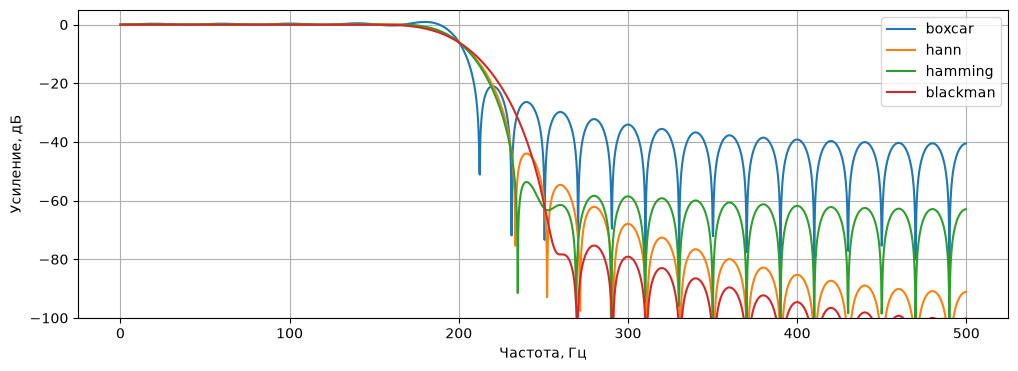

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

%matplotlib inline
np.random.seed(6)
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True})
fs = 1000

def db(x):
    return 20*np.log10(abs(x) + 1e-12)

def spectrum(x, fs):
    amp = abs(np.fft.rfft(x))/len(x)
    amp[1:(len(x)+1)//2] *= 2
    return np.fft.rfftfreq(len(x), 1/fs), amp

def characteristic(b, a, fs):
    f = (np.arange(2048)+0.5)*fs/4096
    _, H = signal.freqz(b, a, worN=f, fs=fs)
    valid = abs(H) > 1e-5
    gd = np.full(len(f), np.nan)
    _, gd[valid] = signal.group_delay((b, a), w=f[valid], fs=fs)
    return f, H, gd

def width_90_10(f, amp):
    f90 = f[np.where(amp <= 0.9)[0][0]]
    f10 = f[np.where(amp <= 0.1)[0][0]]
    return f90, f10, f10-f90

for window in ['boxcar', 'hann', 'hamming', 'blackman']:
    b = signal.firwin(51, 200, window=window, fs=fs)
    f, H = signal.freqz(b, fs=fs, worN=2048)
    plt.plot(f, db(H), label=window)
plt.xlabel('Частота, Гц')
plt.ylabel('Усиление, дБ')
plt.ylim(-100, 5)
plt.legend()
plt.show()

**Вопросы:** Какое окно обеспечивает наилучшее подавление в полосе заграждения? Какое – самую крутую переходную полосу? Как это связано с формой окна?

На графике Блэкман лучше подавляет частоты вдали от среза, но переход шире. Прямоугольное окно даёт более резкий срез и большие боковые лепестки. плавные края окна уменьшают лепестки, но расширяют основной пик.

### Задание 1.2. Влияние длины фильтра
Для окна Хемминга спроектируйте ФНЧ с fc=200 Гц, fs=1000 Гц, с длинами 21, 51, 101. Постройте АЧХ на одном графике.


L=21: задержка 10 отсч., ширина 0.9→0.1 = 90.8 Гц
L=51: задержка 25 отсч., ширина 0.9→0.1 = 36.4 Гц
L=101: задержка 50 отсч., ширина 0.9→0.1 = 18.2 Гц


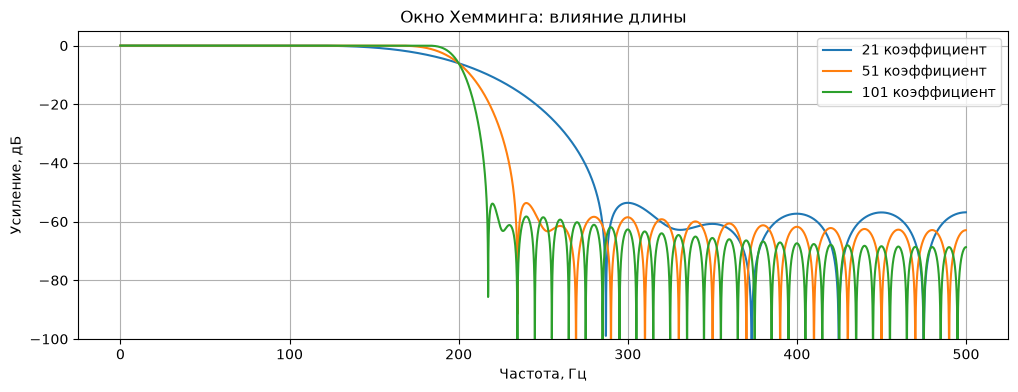

In [2]:
for length in [21, 51, 101]:
    b = signal.firwin(length, 200, window='hamming', fs=fs)
    f, H = signal.freqz(b, [1], worN=8192, fs=fs)
    plt.plot(f, db(H), label=f'{length} коэффициент')
    print(f'L={length}: задержка {(length-1)/2:.0f} отсч., ширина 0.9→0.1 = {width_90_10(f, abs(H))[2]:.1f} Гц')
plt.xlabel('Частота, Гц')
plt.ylabel('Усиление, дБ')
plt.ylim(-100, 5)
plt.title('Окно Хемминга: влияние длины')
plt.legend()
plt.show()

**Вопрос:** Как увеличение длины влияет на крутизну среза и на уровень боковых лепестков?

Чем длиннее фильтр, тем уже переходная полоса. Уровень боковых лепестков в основном задаёт само окно, поэтому он меняется не так сильно. Задержка у нас растёт: 10, 25 и 50 отсчётов для длин 21, 51 и 101.


### Задание 1.3. Синтез ФВЧ и полосового фильтра методом окон
Используя тот же оконный метод, спроектируйте:
- ФВЧ с fc=200 Гц (длина 51, окно Хемминга);
- полосовой фильтр с полосой пропускания 200–300 Гц (длина 51, окно Хемминга).

Постройте АЧХ обоих фильтров.


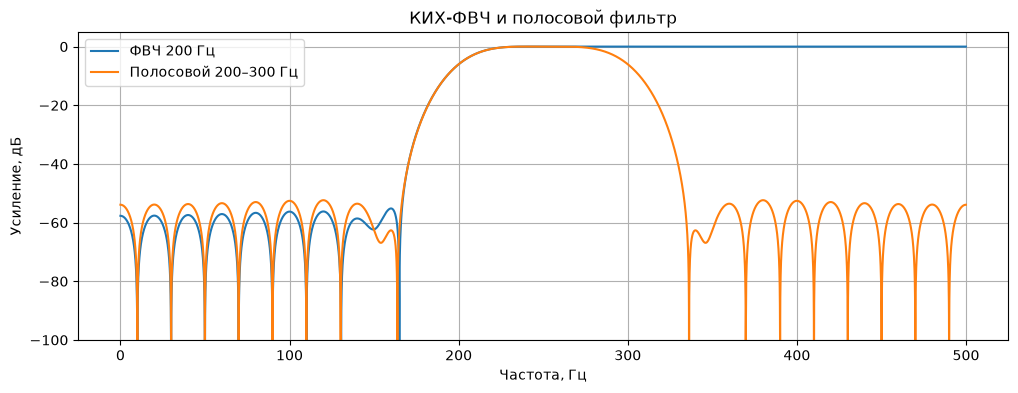

In [3]:
b_hp = signal.firwin(51, 200, window='hamming', pass_zero=False, fs=fs)
b_bp = signal.firwin(51, [200, 300], window='hamming', pass_zero=False, fs=fs)
for label, b in [('ФВЧ 200 Гц', b_hp), ('Полосовой 200–300 Гц', b_bp)]:
    f, H = signal.freqz(b, [1], worN=8192, fs=fs)
    plt.plot(f, db(H), label=label)
plt.xlabel('Частота, Гц')
plt.ylabel('Усиление, дБ')
plt.ylim(-100, 5)
plt.title('КИХ-ФВЧ и полосовой фильтр')
plt.legend()
plt.show()

Подайте на спроектированные фильтры сигнал: сумма синусоид 100, 250 и 350 Гц (амплитуды 1, 0.8, 0.6). Постройте спектры до и после фильтрации (в логарифмическом масштабе).

Исходный : A100, A250, A350 = [1.  0.8 0.6]
ФВЧ : A100, A250, A350 = [0.00154 0.80004 0.59959]
Полосовой : A100, A250, A350 = [2.35e-03 8.00e-01 4.40e-04]


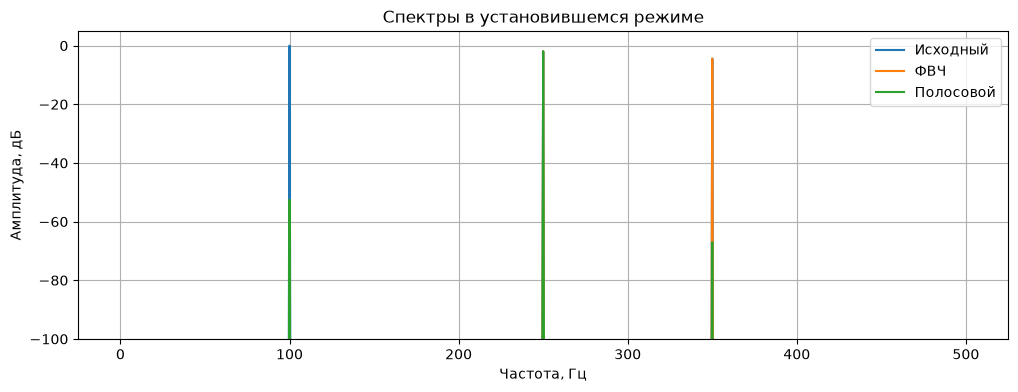

In [4]:
t = np.arange(3*fs)/fs
x = np.sin(2*np.pi*100*t) + .8*np.sin(2*np.pi*250*t) + .6*np.sin(2*np.pi*350*t)
for label, y in [('Исходный', x), ('ФВЧ', signal.lfilter(b_hp, [1], x)), ('Полосовой', signal.lfilter(b_bp, [1], x))]:
    # Последняя секунда без начального переходного участка.
    f, amp = spectrum(y[-fs:], fs)
    plt.plot(f, db(amp), label=label)
    print(label, ': A100, A250, A350 =', np.round(amp[[100, 250, 350]], 5))
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда, дБ')
plt.ylim(-100, 5)
plt.title('Спектры в установившемся режиме')
plt.legend()
plt.show()

**Вопрос:** Объясните полученные результаты.

ФВЧ убрал 100 Гц и оставил 250 и 350 Гц. Полосовой оставил в основном 250 Гц. Спектр беру после начала записи, чтобы запуск фильтра меньше мешал сравнению.

## Часть 2. Равноволновой синтез КИХ-фильтров (Паркса–МакКлеллана)

### Задание 2.1. Проектирование оптимального ФНЧ
Используя `signal.remez`, спроектируйте ФНЧ с параметрами:
- частота дискретизации 1000 Гц,
- полоса пропускания 0–150 Гц,
- полоса заграждения 250–500 Гц,
- длина фильтра 21.

Постройте АЧХ (в линейном и логарифмическом масштабах) и сравните её с АЧХ КИХ-фильтра, полученного методом окон (окно Хемминга, та же длина, fc=200 Гц).

remez размах в пропускании: 0.023


Хемминга размах в пропускании: 0.079


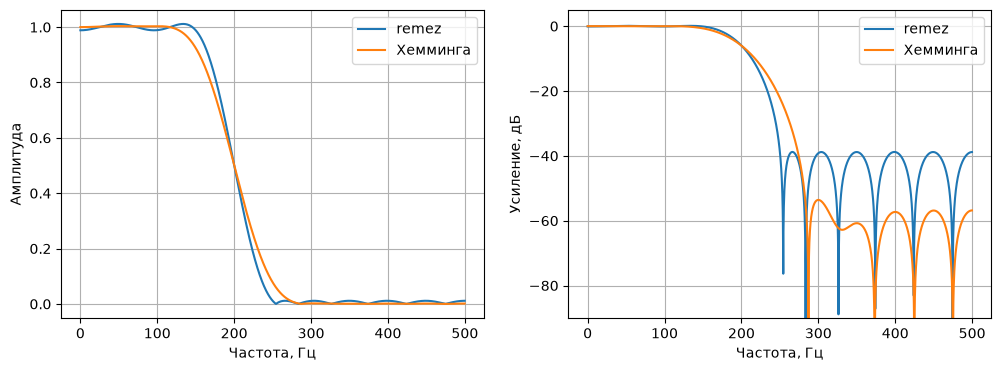

In [5]:
b_remez = signal.remez(21, [0, 150, 250, 500], [1, 0], fs=fs)
b_hamming = signal.firwin(21, 200, window='hamming', fs=fs)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, b in [('remez', b_remez), ('Хемминга', b_hamming)]:
    f, H = signal.freqz(b, fs=fs, worN=2048)
    axes[0].plot(f, abs(H), label=name)
    axes[1].plot(f, db(H), label=name)
    print(name, 'размах в пропускании:', round(np.ptp(abs(H[f <= 150])), 3))
for ax, ylabel in zip(axes, ['Амплитуда', 'Усиление, дБ']):
    ax.set(xlabel='Частота, Гц', ylabel=ylabel)
    ax.legend()
axes[1].set_ylim(-90, 5)
plt.show()


**Вопросы:** Какой фильтр имеет более крутой срез? Каковы пульсации в полосе пропускания?

remez дал более крутой срез. В полосе пропускания у него заметна равномерная рябь, но её размах тут около 0,023 против 0,079 у Хемминга. То есть на выбранной полосе remez оказался точнее, хотя совсем ровной АЧХ не получилось.

### Задание 2.2. Зависимость от ширины переходной полосы

Поменяйте верхнюю частоту полосы пропускания и нижнюю частоту полосы заграждения так, чтобы их среднее оставалось равным 200 Гц. Постройте АЧХ получившегося фильтра. Подберите ширину переходной области (разности нижней частоты полосы заграждения и верхней частоты полосы пропускания) так, чтобы уровень подавления в полосе заграждения у равноволнового фильтра совпал с оконным фильтром Хемминга.


Хемминга, подавление от 250 Гц: 22.1 дБ
Ширина: 30 подавление: 17.0 дБ
Ширина: 46 подавление: 22.2 дБ
Ширина: 60 подавление: 26.6 дБ
Ширина: 100 подавление: 38.8 дБ


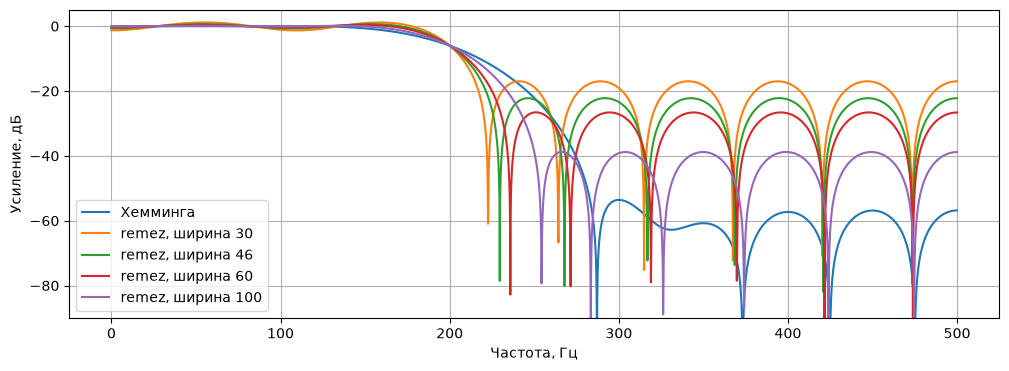

In [6]:
f, H = signal.freqz(b_hamming, fs=fs, worN=4096)
print('Хемминга, подавление от 250 Гц:', round(-max(db(H[f >= 250])), 1), 'дБ')
plt.plot(f, db(H), label='Хемминга')
for width in [30, 46, 60, 100]:
    fp, fst = 200-width/2, 200+width/2
    b = signal.remez(21, [0, fp, fst, 500], [1, 0], fs=fs)
    f, H = signal.freqz(b, fs=fs, worN=4096)
    print('Ширина:', width, 'подавление:', round(-max(db(H[f >= fst])), 1), 'дБ')
    plt.plot(f, db(H), label=f'remez, ширина {width}')
plt.xlabel('Частота, Гц')
plt.ylabel('Усиление, дБ')
plt.ylim(-90, 5)
plt.legend()
plt.show()

**Вопрос:** При какой ширине переходной области уровень подавления в полосе заграждения у равноволнового фильтра совпал с оконным фильтром Хемминга?

Из проверенных вариантов я выбрал ширину 46 Гц: края 177 и 223 Гц. Подавление получилось около 22,2 дБ, у Хемминга от 250 Гц — около 22,1 дБ. Здесь я сравниваю худшее значение в полосе заграждения каждого фильтра.

### Задание 2.3. Управление весами
Для фильтра из задачи 2.1 измените весовые коэффициенты: задайте `weight=[1, 10]` (увеличить вес для полосы заграждения). Постройте новую АЧХ и сравните с предыдущей.


Веса 1:1 размах: 0.023 подавление: 38.8 дБ
Веса 1:10 размах: 0.053 подавление: 51.5 дБ


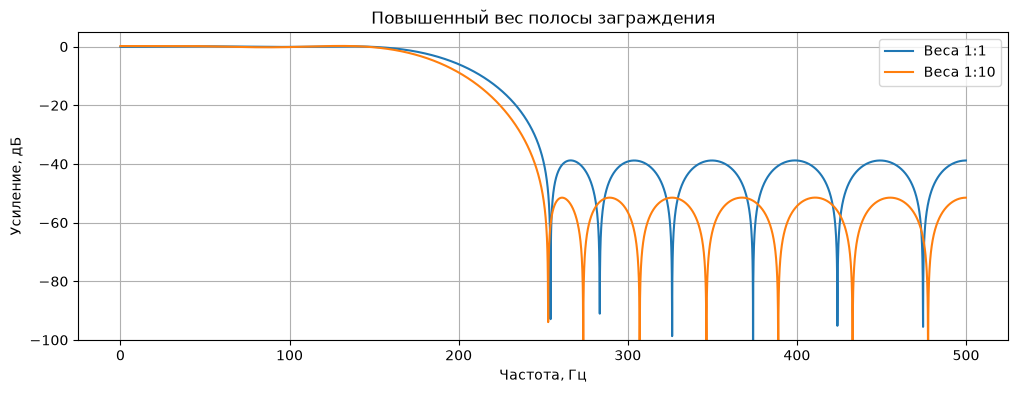

In [7]:
b_weighted = signal.remez(21, [0, 150, 250, 500], [1, 0], weight=[1, 10], fs=fs)
for label, b in [('Веса 1:1', b_remez), ('Веса 1:10', b_weighted)]:
    f, H = signal.freqz(b, [1], worN=8192, fs=fs)
    plt.plot(f, db(H), label=label)
    print(label, 'размах:', round(np.ptp(abs(H[f <= 150])), 3),
          'подавление:', round(-max(db(H[f >= 250])), 1), 'дБ')
plt.xlabel('Частота, Гц')
plt.ylabel('Усиление, дБ')
plt.ylim(-100, 5)
plt.title('Повышенный вес полосы заграждения')
plt.legend()
plt.show()

**Вопрос:** Как изменилось подавление в полосе заграждения и пульсации в полосе пропускания?

С весами 1:10 у нас сильнее подавление в заграждении: примерно 51,5 дБ вместо 38,8. Зато размах в пропускании вырос с 0,023 до 0,053. Получается, больший вес помогает одной полосе за счёт другой.

### Задание 2.4. Сравнение КИХ-фильтров на реальном сигнале
Сгенерируйте сигнал: смесь синусоид 50 Гц, 120 Гц, 220 Гц (амплитуды 1, 0.7, 0.3) + белый шум (дисперсия 0.1), fs=1000 Гц. Пропустите этот сигнал через:
- КИХ-ФНЧ спроектированный методом окон (окно Хемминга, длина 51, fc=150 Гц);
- КИХ-ФНЧ спроектированный методом `remez` (длина 51, полоса пропускания 0–100 Гц, полоса заграждения 200–500 Гц).

Постройте спектры исходного и отфильтрованных сигналов в линейном и логарифмическом масштабе.


Хемминга A120: 0.6935 A220: 0.000329
remez A120: 0.6756 A220: 9e-06


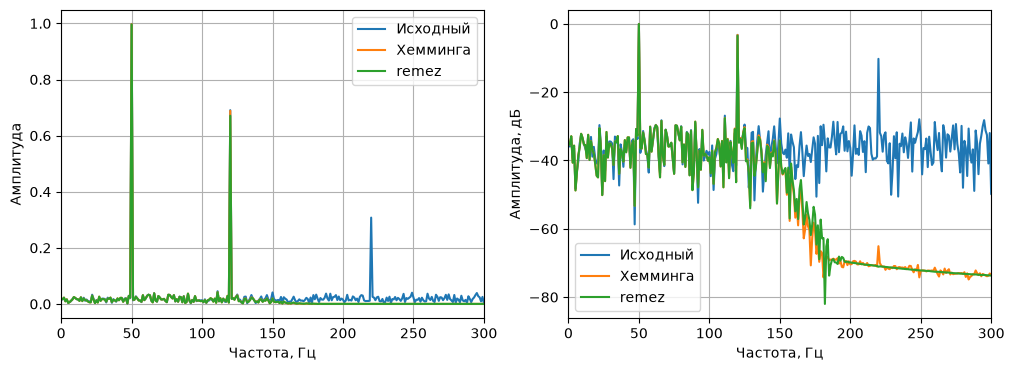

In [8]:
t = np.arange(3*fs)/fs
x = (np.sin(2*np.pi*50*t) + 0.7*np.sin(2*np.pi*120*t)
     + 0.3*np.sin(2*np.pi*220*t) + np.sqrt(0.1)*np.random.randn(len(t)))
filters = {
    'Хемминга': signal.firwin(51, 150, window='hamming', fs=fs),
    'remez': signal.remez(51, [0, 100, 200, 500], [1, 0], fs=fs),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
f, amp = spectrum(x[-fs:], fs)
axes[0].plot(f, amp, label='Исходный')
axes[1].plot(f, db(amp), label='Исходный')
for name, b in filters.items():
    y = signal.lfilter(b, [1], x)
    f, amp = spectrum(y[-fs:], fs)
    axes[0].plot(f, amp, label=name)
    axes[1].plot(f, db(amp), label=name)
    _, H = signal.freqz(b, worN=[120, 220], fs=fs)
    print(name, 'A120:', round(0.7*abs(H[0]), 4), 'A220:', round(0.3*abs(H[1]), 6))
for ax, label in zip(axes, ['Амплитуда', 'Амплитуда, дБ']):
    ax.set(xlabel='Частота, Гц', ylabel=label, xlim=(0, 300))
    ax.legend()
plt.show()

**Вопросы:** Какой фильтр лучше подавил 220 Гц и шум? Какой лучше сохранил 120 Гц? На сколько отличаются амплитуды 120 Гц сигнала от исходных для каждого из фильтров?


remez сильнее подавил тон 220 Гц. Шум на спектрах тоже стал меньше у обоих фильтров. Зато 120 Гц лучше сохранило окно Хемминга: осталось около 0,6935 вместо 0,7, потеря 0,9%. У remez осталось около 0,6756, потеря 3,5%: эта частота у него уже в переходной полосе.

## Часть 3. Синтез БИХ-фильтров

### Задание 3.1. Баттерворт, Чебышев, эллиптический – сравнение АЧХ
Спроектируйте ФНЧ с частотой среза 200 Гц (fs=1000 Гц) следующих типов (порядок 4):
- Баттерворт (`butter`);
- Чебышев I с пульсациями 1 дБ (`cheby1`);
- Чебышев II с затуханием 40 дБ в полосе заграждения (`cheby2`);
- Эллиптический с пульсациями 1 дБ и затуханием 40 дБ (`ellip`).

Постройте АЧХ всех фильтров на одном графике (в дБ). Сравните:
- крутизну среза,
- пульсации в полосе пропускания и заграждения.

Постройте и сравните фазовые характеристики (ФЧХ) и групповые задержки.


Баттерворт: АЧХ на 100, 200, 250 Гц (дБ): [-1.000e-02 -3.010e+00 -1.142e+01]
Чебышев I: АЧХ на 100, 200, 250 Гц (дБ): [ -0.09  -1.   -17.47]
Чебышев II: АЧХ на 100, 200, 250 Гц (дБ): [ -1.42 -40.   -40.05]
Эллиптический: АЧХ на 100, 200, 250 Гц (дБ): [-1.000e-02 -1.000e+00 -2.743e+01]


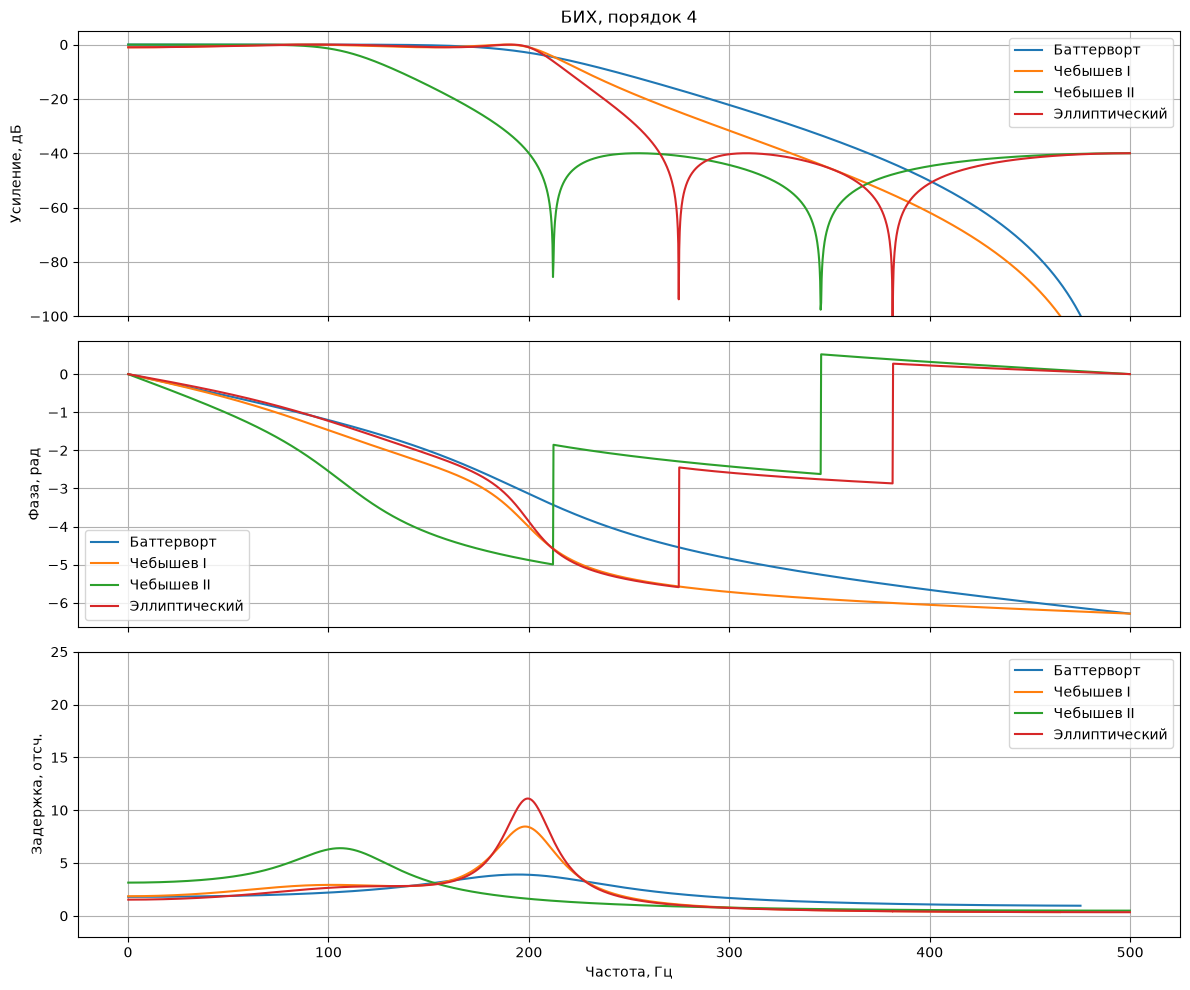

In [9]:
iir_filters = {
    'Баттерворт': signal.butter(4, 200, fs=fs),
    'Чебышев I': signal.cheby1(4, 1, 200, fs=fs),
    'Чебышев II': signal.cheby2(4, 40, 200, fs=fs),
    'Эллиптический': signal.ellip(4, 1, 40, 200, fs=fs),
}
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for label, (b, a) in iir_filters.items():
    f, H, gd = characteristic(b, a, fs)
    axes[0].plot(f, db(H), label=label)
    axes[1].plot(f, np.unwrap(np.angle(H)), label=label)
    axes[2].plot(f, gd, label=label)
    _, values = signal.freqz(b, a, worN=[100, 200, 250], fs=fs)
    print(f'{label}: АЧХ на 100, 200, 250 Гц (дБ): {np.round(db(values), 2)}')
axes[0].set(ylabel='Усиление, дБ', ylim=(-100, 5), title='БИХ, порядок 4')
axes[1].set(ylabel='Фаза, рад')
axes[2].set(xlabel='Частота, Гц', ylabel='Задержка, отсч.', ylim=(-2, 25))
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

**Вопросы:** Какой фильтр даёт самый крутой спад? Какой имеет наименьшие фазовые искажения в полосе пропускания?


Самый резкий переход у меня получился у эллиптического фильтра. Баттерворт более плавный, и задержка в его рабочей полосе меняется спокойнее. Строго линейной фазы у этих БИХ нет. Ещё у Чебышева II частота 200 Гц означает край заграждения, поэтому все четыре фильтра нельзя сравнивать только по одной точке.

### Задание 3.2. Влияние порядка на характеристики БИХ-фильтра
Для фильтра Баттерворта с fc=200 Гц, fs=1000 Гц возьмите порядки 2, 4, 6. Постройте АЧХ и групповую задержку.

Постройте также расположение полюсов этих фильтров на z-плоскости (`signal.tf2zpk` или `signal.sos2zpk` для формата 'sos') вместе с единичной окружностью.

N=2: максимальный радиус полюса 0.44251, задержка при 190 Гц 1.511 отсч.
N=4: максимальный радиус полюса 0.68288, задержка при 190 Гц 3.894 отсч.
N=6: максимальный радиус полюса 0.77778, задержка при 190 Гц 6.526 отсч.


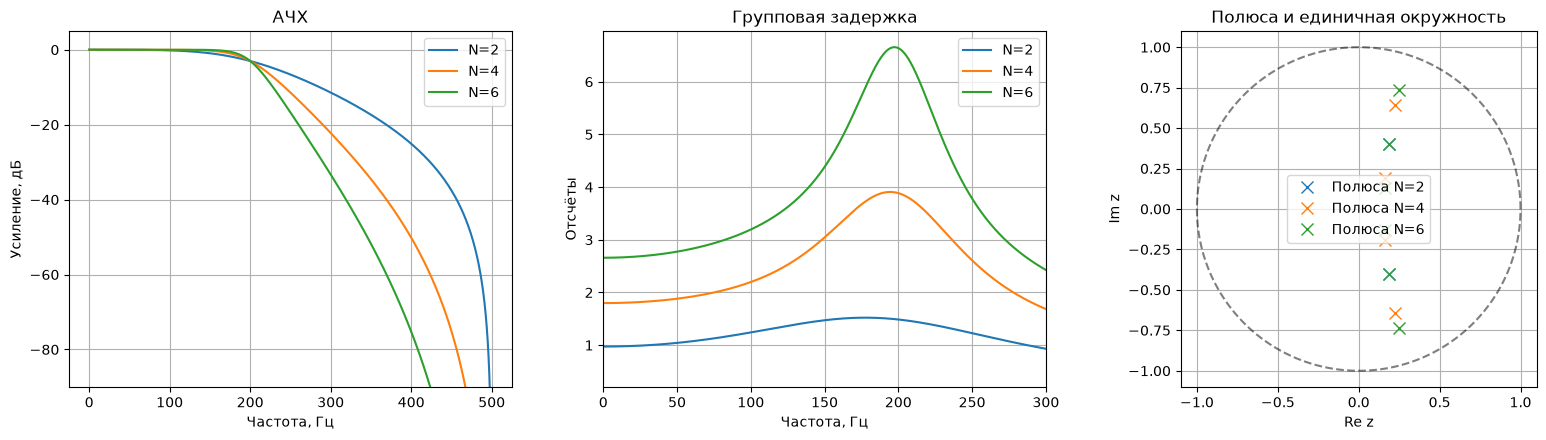

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
circle = np.exp(1j*np.linspace(0, 2*np.pi, 400))
axes[2].plot(circle.real, circle.imag, 'k--', alpha=.5)
for order in [2, 4, 6]:
    b, a = signal.butter(order, 200, fs=fs)
    f, H, gd = characteristic(b, a, fs)
    axes[0].plot(f, db(H), label=f'N={order}')
    axes[1].plot(f, gd, label=f'N={order}')
    z, p, k = signal.tf2zpk(b, a)
    axes[2].plot(p.real, p.imag, 'x', ms=9, label=f'Полюса N={order}')
    print(f'N={order}: максимальный радиус полюса {max(abs(p)):.5f}, задержка при 190 Гц {np.interp(190, f, gd):.3f} отсч.')
axes[0].set(title='АЧХ', xlabel='Частота, Гц', ylabel='Усиление, дБ', ylim=(-90, 5))
axes[1].set(title='Групповая задержка', xlabel='Частота, Гц', ylabel='Отсчёты', xlim=(0, 300))
axes[2].set(title='Полюса и единичная окружность', xlabel='Re z', ylabel='Im z', aspect='equal')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

**Вопросы:** Как увеличение порядка влияет на крутизну среза и на групповую задержку в полосе пропускания? Как с ростом порядка меняется расположение полюсов и как это объясняет рост групповой задержки вблизи частоты среза?

С ростом порядка я вижу более крутой спад, но и задержка возле среза растёт. Полюсов становится больше, часть из них ближе к единичной окружности, поэтому хвост затухает дольше. Во всех наших вариантах полюса внутри окружности, фильтры устойчивы.

### Задание 3.3. Преобразование типа БИХ-фильтра (ФНЧ → ФВЧ, полосовой)
Спроектируйте Баттерворта 4-го порядка:
- ФНЧ с fc=200 Гц;
- ФВЧ с fc=200 Гц (используйте `btype='high'`);
- полосовой с полосой 200–300 Гц.

Подайте на них сигнал: сумма синусоид 100, 250, 400 Гц. Постройте спектры после фильтрации.


ФНЧ: A100, A250, A400 = [0.9992 0.2684 0.0031]
ФВЧ: A100, A250, A400 = [0.04   0.9633 1.    ]
Полосовой: A100, A250, A400 = [0.0031 1.     0.0031]


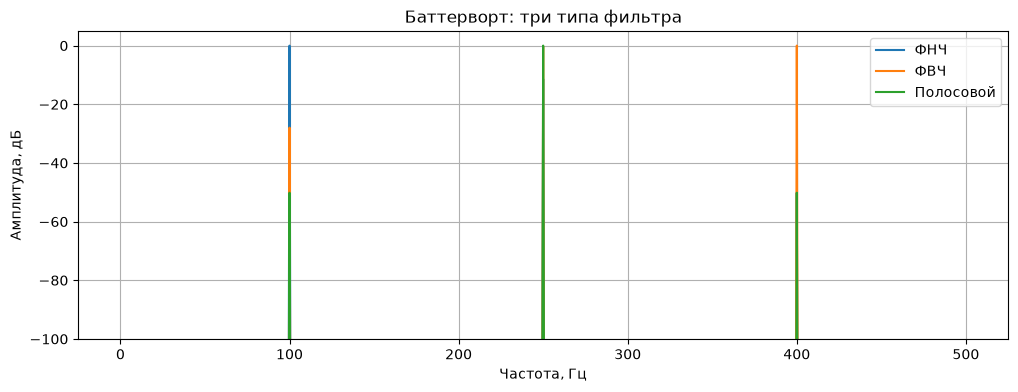

In [11]:
t = np.arange(3*fs)/fs
x = sum(np.sin(2*np.pi*f*t) for f in [100, 250, 400])
types = {
    'ФНЧ': signal.butter(4, 200, btype='low', fs=fs),
    'ФВЧ': signal.butter(4, 200, btype='high', fs=fs),
    'Полосовой': signal.butter(4, [200, 300], btype='bandpass', fs=fs),
}
for label, (b, a) in types.items():
    y = signal.lfilter(b, a, x)
    f, amp = spectrum(y[-fs:], fs)
    plt.plot(f, db(amp), label=label)
    print(f'{label}: A100, A250, A400 = {np.round(amp[[100,250,400]], 4)}')
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда, дБ')
plt.ylim(-100, 5)
plt.title('Баттерворт: три типа фильтра')
plt.legend()
plt.show()

**Вопрос:** Какие составляющие подавлены, а какие пропущены в каждом случае?

ФНЧ оставил в основном 100 Гц, ФВЧ — 250 и 400 Гц, а полосовой — 250 Гц. Совсем нулевых остатков мы тут не ждём: у фильтров конечная крутизна спада. Для полосового Баттерворта параметр порядка 4 даёт итоговый порядок 8.

### Задание 3.4. Применение БИХ-фильтра к зашумлённому сигналу
Сгенерируйте сигнал: синусоида 50 Гц + белый шум с дисперсией 0.2, fs=1000 Гц, длительность 1 с. Спроектируйте эллиптический ФНЧ с fc=100 Гц (порядок 6, пульсации 1 дБ, затухание 40 дБ). Примените фильтр с помощью `lfilter` и `filtfilt`. Постройте на одном графике исходный и отфильтрованные сигналы (временные области, первые 0.2 с), а также их спектры. Сравните задержку и подавление шума.


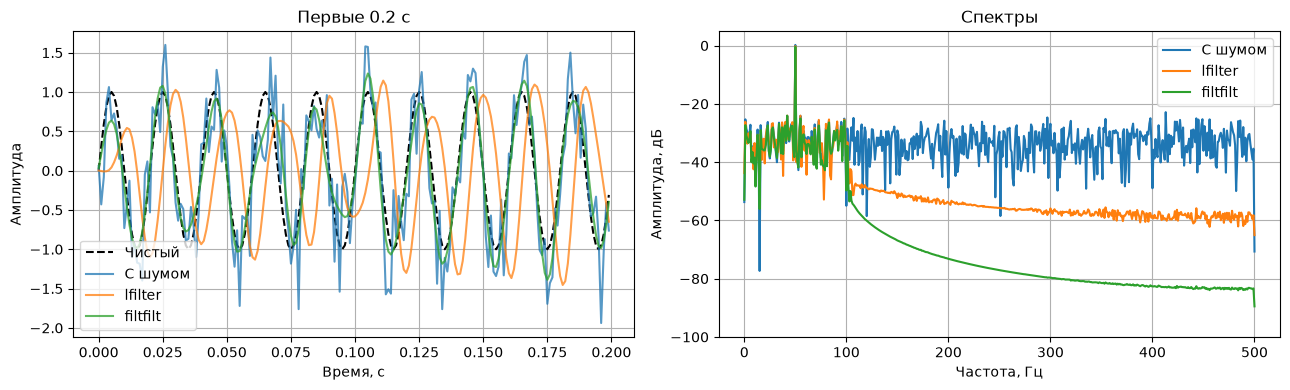

In [12]:
t = np.arange(fs)/fs
clean = np.sin(2*np.pi*50*t)
noise = np.sqrt(.2)*np.random.randn(fs)
x = clean + noise
b, a = signal.ellip(6, 1, 40, 100, fs=fs)
y_one = signal.lfilter(b, a, x)
y_zero = signal.filtfilt(b, a, x)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(t[:200], clean[:200], 'k--', label='Чистый')
for label, y in [('С шумом', x), ('lfilter', y_one), ('filtfilt', y_zero)]:
    axes[0].plot(t[:200], y[:200], alpha=.75, label=label)
    f, amp = spectrum(y, fs)
    axes[1].plot(f, db(amp), label=label)
axes[0].set(title='Первые 0.2 с', xlabel='Время, с', ylabel='Амплитуда')
axes[1].set(title='Спектры', xlabel='Частота, Гц', ylabel='Амплитуда, дБ', ylim=(-100, 5))
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

**Вопрос:** Почему `filtfilt` даёт нулевой фазовый сдвиг?

Мы фильтруем сначала вперёд, потом назад, поэтому фазовые сдвиги компенсируются. У меня вершины после `filtfilt` почти не смещаются относительно чистой синусоиды. При этом модуль АЧХ становится квадратом исходного, а на краях записи всё равно могут быть искажения. Для такого прохода нужен весь сигнал.

## Часть 4. Сравнение КИХ и БИХ фильтров одинакового порядка

### Задание 4.1. Сравнение характеристик
Спроектируйте:
- КИХ-ФНЧ методом окон (окно Хемминга, длина 51, fc=200 Гц);
- БИХ-ФНЧ Баттерворта 4-го порядка (fc=200 Гц).

Постройте для них на одном графике:
- отдельно АЧХ (в дБ),
- отдельно групповую задержку.


КИХ 51 ширина перехода: 36.4 Гц
БИХ 4 ширина перехода: 116.7 Гц
БИХ 8 ширина перехода: 58.3 Гц
БИХ 13 ширина перехода: 35.6 Гц


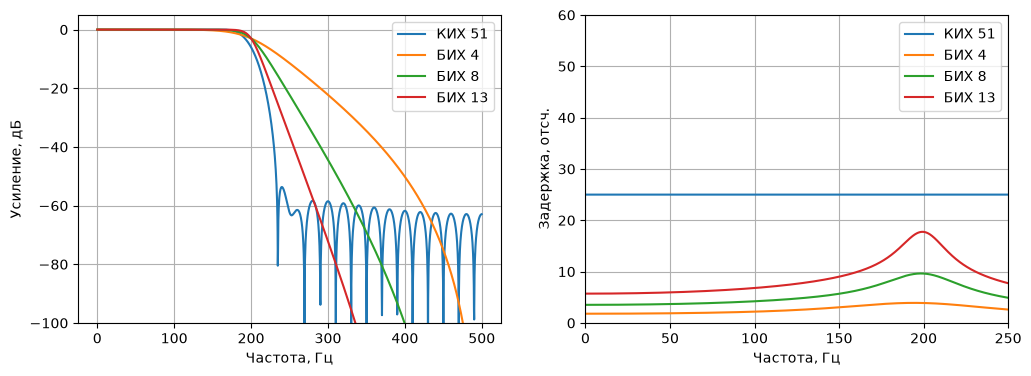

In [13]:
fir_compare = signal.firwin(51, 200, window='hamming', fs=fs)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
filters = [('КИХ 51', fir_compare, [1])]
for order in [4, 8, 13]:
    b, a = signal.butter(order, 200, fs=fs)
    filters.append((f'БИХ {order}', b, a))
for name, b, a in filters:
    f, H, gd = characteristic(b, a, fs)
    axes[0].plot(f, db(H), label=name)
    axes[1].plot(f, gd, label=name)
    print(name, 'ширина перехода:', round(width_90_10(f, abs(H))[2], 1), 'Гц')
axes[0].set(xlabel='Частота, Гц', ylabel='Усиление, дБ', ylim=(-100, 5))
axes[1].set(xlabel='Частота, Гц', ylabel='Задержка, отсч.', xlim=(0, 250), ylim=(0, 60))
for ax in axes:
    ax.legend()
plt.show()

**Вопросы:** Какой фильтр имеет более крутой срез? Какой имеет постоянную групповую задержку? Какой вносит меньшие фазовые искажения? Какой требует меньше вычислений? Попробуйте увеличить порядок фильтра Баттерворта. При каком порядке крутизна среза его АЧХ становится сравнимой с КИХ-фильтром? Растут или уменьшаются при этом фазовые искажения?


КИХ 51 у меня дал более резкий срез, чем БИХ порядка 4. У КИХ постоянная задержка 25 отсчётов, у БИХ она меняется с частотой, зато вычислений меньше. Из проверенных порядков Баттерворта 13 оказался близким по ширине перехода: примерно 36 Гц. Но задержка возле среза стала больше и менее равномерной. Кстати, у КИХ 51 коэффициент означает порядок 50.

### Задание 4.2. Применение к реальному сигналу
Сгенерируйте сигнал: короткий прямоугольный импульс длительностью 10 мс, а также высокочастотная синусоидальная помеха 400 Гц. Частоту дискретизации возьмите fs=10000 Гц.

Примените оба фильтра (КИХ и БИХ из предыдущего пункта). Постройте исходный и отфильтрованные сигналы.


КИХ: подавление 400 Гц 20.60 дБ, остаточная амплитуда помехи 0.02799
БИХ: подавление 400 Гц 24.24 дБ, остаточная амплитуда помехи 0.01842


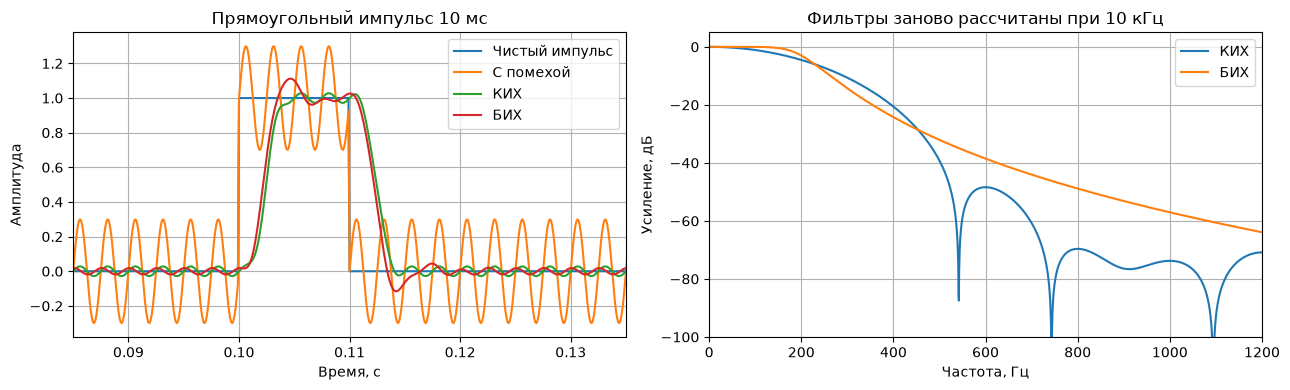

In [14]:
fs_pulse = 10000
t_pulse = np.arange(int(.3*fs_pulse))/fs_pulse
pulse = ((t_pulse >= .1) & (t_pulse < .11)).astype(float)
interference = .3*np.sin(2*np.pi*400*t_pulse)
x_pulse = pulse + interference
# Для новой частоты дискретизации пересчитываю фильтры.
b_fir_pulse = signal.firwin(51, 200, window='hamming', fs=fs_pulse)
b_iir_pulse, a_iir_pulse = signal.butter(4, 200, fs=fs_pulse)
y_fir_pulse = signal.lfilter(b_fir_pulse, [1], x_pulse)
y_iir_pulse = signal.lfilter(b_iir_pulse, a_iir_pulse, x_pulse)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, y in [('Чистый импульс', pulse), ('С помехой', x_pulse), ('КИХ', y_fir_pulse), ('БИХ', y_iir_pulse)]:
    axes[0].plot(t_pulse, y, label=label)
for label, b, a in [('КИХ', b_fir_pulse, [1]), ('БИХ', b_iir_pulse, a_iir_pulse)]:
    f_p, H = signal.freqz(b, a, worN=8192, fs=fs_pulse)
    axes[1].plot(f_p, db(H), label=label)
    _, H400 = signal.freqz(b, a, worN=[400], fs=fs_pulse)
    print(f'{label}: подавление 400 Гц {-db(H400[0]):.2f} дБ, остаточная амплитуда помехи {.3*abs(H400[0]):.5f}')
axes[0].set(title='Прямоугольный импульс 10 мс', xlabel='Время, с', ylabel='Амплитуда', xlim=(.085, .135))
axes[1].set(title='Фильтры заново рассчитаны при 10 кГц', xlabel='Частота, Гц', ylabel='Усиление, дБ', xlim=(0, 1200), ylim=(-100, 5))
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

**Вопросы:** Какой фильтр лучше сохранил форму импульсов? Какой лучше подавил помеху?

Оба фильтра сгладили края нашего импульса. КИХ сохранил более симметричную форму с постоянной задержкой, а у БИХ заметнее хвост и выбросы. Зато помеху 400 Гц БИХ подавил сильнее: около 24 дБ против 21 дБ. Я пересчитал коэффициенты для 10 кГц, иначе физическая частота среза тоже изменилась бы.

## Общий вывод

При проектировании фильтра важна не только частота среза. Окно, длина, допуски по ряби и задержка заметно меняют результат. Мне было полезнее всего сравнивать сразу график сигнала и АЧХ: так видно, почему вместе с помехой иногда ослабляется и нужная часть. КИХ проще понять по постоянной задержке, а БИХ даёт сильную фильтрацию с небольшим числом коэффициентов. Но универсального лучшего варианта в этих опытах не получилось.